# Differential cryptanalysis of PRESENT with SAT

**EPITA 2026 - Constraint Programming - Project F2**

In [1]:
# Imports
import sys
sys.path.insert(0, '.')

from present_sat.present import SBOX, P, DDT, encrypt, generate_round_keys, validate_trail
from present_sat.encoding import (
    build_model, build_weighted_model,
    _SBOX_PI_TEMPLATES, _SBOX_WEIGHT_TEMPLATES,
    trail_weight, trail_active_sboxes
)
from present_sat.search import find_min_active_sbox, find_min_trail_weight, ACTIVE_BOUNDS

import json
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D


In [2]:
# Load the benchmark file
with open("benchmark.json", "r") as f:
    benchmark = json.load(f)

## 1 - Introduction

### 1.a - Context

**Differential cryptanalysis** is a generic attack against block ciphers, introduced by Biham and Shamir in 1991. It studies how a difference $\Delta = M \oplus M'$ between two plaintexts propagates through the rounds of the cipher.

A *differential trail* is a sequence $(\Delta_0, \Delta_1, \ldots, \Delta_R)$ where $\Delta_r$ is the difference between two states after round $r$. Each transition $\Delta_r \to \Delta_{r+1}$ is probabilistic and depends on the non-linear components of the cipher.

The **weight** of a trail is defined as $w = -\log_2(\text{prob})$, where $\text{prob} = \prod_i p_i$ is the product of the probabilities of each transition. A high weight means that the trail is unlikely, and therefore hard to exploit.

Conversely, a low-weight trail has a high probability: an attacker can collect enough plaintext pairs following this trail to deduce key bits, far more efficiently than an exhaustive search.

**Security criterion:** if $w_{\min}(R) > n$ (block size in bits), the cipher resists differential cryptanalysis over $R$ rounds. Indeed, exploiting a trail of weight $w$ requires about $2^{w+1}$ plaintext pairs. For PRESENT ($n = 64$), the plaintext space has size $2^{64}$: as soon as $w > 64$, the data complexity exceeds $2^{65}$, which is out of reach for any attacker.


### 1.b - The PRESENT cipher

PRESENT (Bogdanov et al., 2007) is an ultra-lightweight block cipher designed for constrained environments (IoT, RFID). It operates on **64-bit** blocks with an **80-bit** key and consists of **31** identical rounds.

#### Architecture - SPN structure

Each round chains three operations:

1. **AddRoundKey**: XOR of the current state with the 64 bits of round key extracted from the key register
2. **sBoxLayer**: parallel application of 16 identical S-boxes $S : \{0,1\}^4 \to \{0,1\}^4$, one per nibble
3. **pLayer**: fixed bit permutation $P : \{0,\ldots,63\} \to \{0,\ldots,63\}$ that mixes the outputs of the 16 S-boxes (the last round does not apply the pLayer)

#### Difference propagation

In an SPN, differences propagate probabilistically through the S-boxes. For an S-box $S$, the probability that input difference $a$ produces output difference $b$ is:
$$\Pr[\Delta_{\text{out}} = b \mid \Delta_{\text{in}} = a] = \frac{\#\{x \mid S(x) \oplus S(x \oplus a) = b\}}{2^n}$$
This quantity equals $\text{DDT}[a][b] / 16$, where the DDT is built in section 2.

#### Key property for differential cryptanalysis

The `AddRoundKey` operation **vanishes** in the computation of differences. For two texts $A$ and $A' = A \oplus \Delta$:
$$\Delta(A \oplus K) = (A \oplus K) \oplus (A' \oplus K) = A \oplus A' = \Delta$$
Difference propagation is therefore **independent of the secret key**, which makes the analysis possible without knowing it.

#### Active S-boxes and lower bound on the weight

The `pLayer` is a linear permutation: the output difference is entirely determined by the input difference, $\Delta_{\text{out}} = P(\Delta_{\text{in}})$, with probability 1. `AddRoundKey` does not modify differences either, as shown above. **All the probabilistic uncertainty of a trail therefore comes from the S-boxes alone.**

The weight of a trail then decomposes as a sum over the S-boxes traversed during the $R$ rounds:
$$w(\Delta_0, \ldots, \Delta_R) = \sum_{r=0}^{R-1} \sum_{i=1}^{16} w_S\!\left(\Delta_r^{(i)} \to \Delta_{r+1}^{(i)}\right)$$
where $\Delta_r^{(i)}$ is the input difference of the $i$-th S-box at round $r$.

An S-box is called *active* in a trail if its input difference is non-zero. An inactive S-box undergoes the transition $0 \to 0$, which is deterministic and has zero weight; it does not contribute to the total weight.

Examining the DDT of PRESENT (built in section 2) shows that every non-trivial transition has a probability of at most $2^{-2}$. In other words, **each active S-box contributes a weight of at least 2**. Denoting by $A(R)$ the minimum number of active S-boxes over all $R$-round trails, we obtain:
$$w_{\min}(R) \geq 2 \cdot A(R)$$

This bound is useful in two ways:

- **It is easier to compute than $w_{\min}$.** Determining $A(R)$ only involves the propagation of active bits through the `pLayer` - a purely combinatorial problem on binary variables (S-box active or not), independent of the DDT values. The corresponding SAT model is much lighter.
- **It provides an a priori security argument.** If we prove $A(R) \geq k$, then no $R$-round trail can have a weight below $2k$, without having to enumerate them. This is the argument used by Bogdanov et al. in the PRESENT specification to justify the resistance of the cipher.

However, this bound is not always reached: some configurations force transitions of weight greater than 2 (for example when the active input and output bits are constrained to positions incompatible with the optimal DDT transitions). Computing $w_{\min}(R)$ exactly - and not merely bounding it - requires encoding the full DDT in the model. The two quantities $A(R)$ and $w_{\min}(R)$ will therefore be handled by distinct SAT models in the rest of the project.


In [3]:
# The PRESENT S-box and P-layer

print("PRESENT S-box:")
print(' '.join(f'{v:X}' for v in range(16)))
print(' '.join(f'{v:X}' for v in SBOX))
print()
print("P-layer (bit i -> position P[i]):")
for row in range(4):
    print(' '.join(f'{P[16*row+col]:2d}' for col in range(16)))

PRESENT S-box:
0 1 2 3 4 5 6 7 8 9 A B C D E F
C 5 6 B 9 0 A D 3 E F 8 4 7 1 2

P-layer (bit i -> position P[i]):
 0 16 32 48  1 17 33 49  2 18 34 50  3 19 35 51
 4 20 36 52  5 21 37 53  6 22 38 54  7 23 39 55
 8 24 40 56  9 25 41 57 10 26 42 58 11 27 43 59
12 28 44 60 13 29 45 61 14 30 46 62 15 31 47 63



**PRESENT S-box** (hexadecimal values, generated from `present_sat/present.py`):

| x | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | A | B | C | D | E | F |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| S(x) | C | 5 | 6 | B | 9 | 0 | A | D | 3 | E | F | 8 | 4 | 7 | 1 | 2 |

**PRESENT bit permutation $P$**: bit $i$ is sent to position $P(i)$ (row: $i$ = 16 × row + column):

| i | +0 | +1 | +2 | +3 | +4 | +5 | +6 | +7 | +8 | +9 | +10 | +11 | +12 | +13 | +14 | +15 |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 0 | 0 | 16 | 32 | 48 | 1 | 17 | 33 | 49 | 2 | 18 | 34 | 50 | 3 | 19 | 35 | 51 |
| 16 | 4 | 20 | 36 | 52 | 5 | 21 | 37 | 53 | 6 | 22 | 38 | 54 | 7 | 23 | 39 | 55 |
| 32 | 8 | 24 | 40 | 56 | 9 | 25 | 41 | 57 | 10 | 26 | 42 | 58 | 11 | 27 | 43 | 59 |
| 48 | 12 | 28 | 44 | 60 | 13 | 29 | 45 | 61 | 14 | 30 | 46 | 62 | 15 | 31 | 47 | 63 |

In [4]:
# Test vectors from the reference paper (paper 1)
tests = [
    (0x0000000000000000, 0x00000000000000000000, 0x5579C1387B228445),
    (0x0000000000000000, 0xFFFFFFFFFFFFFFFFFFFF, 0xE72C46C0F5945049),
    (0xFFFFFFFFFFFFFFFF, 0x00000000000000000000, 0xA112FFC72F68417B),
    (0xFFFFFFFFFFFFFFFF, 0xFFFFFFFFFFFFFFFFFFFF, 0x3333DCD3213210D2),
]
for pt, k, expected in tests:
    ct = encrypt(pt, generate_round_keys(k))
    status = "ok" if ct == expected else f"ERROR (got {ct:016X})"
    print(f"P={pt:016X}  K={k:020X}  ->  C={ct:016X}  {status}")

P=0000000000000000  K=00000000000000000000  ->  C=5579C1387B228445  ok
P=0000000000000000  K=FFFFFFFFFFFFFFFFFFFF  ->  C=E72C46C0F5945049  ok
P=FFFFFFFFFFFFFFFF  K=00000000000000000000  ->  C=A112FFC72F68417B  ok
P=FFFFFFFFFFFFFFFF  K=FFFFFFFFFFFFFFFFFFFF  ->  C=3333DCD3213210D2  ok


### 1.c - Problem statement

> **Does PRESENT resist differential cryptanalysis, and from how many rounds on?**

More precisely, this project seeks to answer the following questions:

1. What is the **minimum number of active S-boxes** in any differential path over $R$ rounds?
2. What is the **minimum weight** of such a path, i.e. the best attainable differential probability?
3. From which $R$ does this weight exceed 64, making any attack impractical?
4. Is it possible to **automatically extract** an optimal path from the SAT model?

The adopted approach consists in encoding these constraints as a SAT formula and using a solver to obtain exact answers.


### 1.d - Literature and expected results

#### Minimum number of active S-boxes:
Bogdanov et al. (CHES 2007) prove that any differential path over $R$ rounds of PRESENT activates at least $2R$ S-boxes (for $R \geq 2$). Later analyses give the exact minima (see paper 4).

*Values known from the literature, as encoded in `present_sat/search.py` (`ACTIVE_BOUNDS`).*

| R | $\#\{AS_D\}$ |
|---:|---:|
| 1 | 1 |
| 2 | 2 |
| 3 | 4 |
| 4 | 6 |
| 5 | 10 |
| 6 | 12 |
| 7 | 14 |
| 8 | 16 |
| 9 | 18 |
| 10 | 20 |
| 11 | 22 |
| 12 | 24 |
| 13 | 26 |
| 14 | 28 |
| 15 | 30 |
| 16 | 32 |
| 17 | 34 |
| 18 | 36 |
| 19 | 38 |
| 20 | 40 |
| 21 | 42 |
| 22 | 44 |
| 23 | 46 |
| 24 | 48 |
| 25 | 50 |
| 26 | 52 |
| 27 | 54 |
| 28 | 56 |
| 29 | 58 |
| 30 | 60 |
| 31 | 62 |

The minimum number of active S-boxes as a function of the number of rounds is the second column ($\#\{AS_D\}$).

#### Minimum weight of differential trails:
The table below (from the literature - *papers/accelrating-the-best-trail-search-on-aes-like-ciphers.pdf*) gives the minimum differential weights as a function of R:

*The column of interest here is B[R].*

*Values known from the literature, as encoded in `present_sat/search.py` (`WEIGHT_BOUNDS`).*

| R | $\mathbb{B}[R]$ |
|---:|---:|
| 1 | 2 |
| 2 | 4 |
| 3 | 8 |
| 4 | 12 |
| 5 | 20 |
| 6 | 24 |
| 7 | 28 |
| 8 | 32 |
| 9 | 36 |
| 10 | 41 |
| 11 | 46 |
| 12 | 52 |
| 13 | 56 |
| 14 | 62 |
| 15 | 66 |
| 16 | 70 |
| 17 | 74 |
| 18 | 78 |
| 19 | 82 |
| 20 | 86 |
| 21 | 90 |
| 22 | 96 |
| 23 | 100 |
| 24 | 106 |
| 25 | 110 |
| 26 | 116 |
| 27 | 120 |
| 28 | 124 |
| 29 | 128 |
| 30 | 132 |
| 31 | 136 |


Note that from $R > 14$ on, the minimum weight exceeds $64$: $62$ at $R = 14$, then $66$ at $R = 15$.

The computation times published by the authors come from a dedicated DFS *branch-and-bound* search; they are not reproduced here and are not directly comparable to ours (SAT solving, different machine). Here are the times **measured in this project** (single run, seconds, file `benchmark.json`) to find this same minimum weight:

| R | $\mathbb{B}[R]$ found | Kissat (s) | CaDiCaL (s) | Kissat-seq (s) |
|---:|---:|---:|---:|---:|
| 1 | 2 | 0.004 | 0.013 | 0.006 |
| 2 | 4 | 0.030 | 0.024 | 0.011 |
| 3 | 8 | 0.073 | 0.049 | 0.052 |
| 4 | 12 | 0.164 | 0.131 | 0.088 |
| 5 | 20 | 0.717 | 0.649 | 0.170 |
| 6 | 24 | 2.3 | 1.8 | 1.3 |
| 7 | 28 | 1.7 | 2.1 | 0.880 |
| 8 | 32 | 5.7 | 4.6 | 1.4 |
| 9 | 36 | 8.9 | 7.2 | 4.4 |
| 10 | 41 | 27.8 | 30.7 | 12.9 |
| 11 | 46 | 72.3 | 130.8 | 116.1 |
| 12 | 52 | 102.5 | 143.6 | 77.3 |
| 13 | 56 | 208.9 | 443.1 | 120.7 |
| 14 | 62 | 590.0 | 1 306.7 | 453.3 |
| 15 | 66 | 761.2 | 1 702.3 | 373.6 |
| 16 | 70 | 409.4 | 1 124.0 | 353.2 |
| 17 | 74 | 1 590.7 | 4 419.8 | 1 094.2 |
| 18 | 78 | 2 193.8 | 4 454.2 | 1 281.4 |
| 19 | 82 | 2 661.3 | 6 282.6 | 1 265.4 |
| 20 | 86 | 1 025.0 | 1 453.3 | 424.2 |
| 21 | 90 | 4 554.8 | 5 552.8 | 1 750.4 |
| 22 | 96 | 15 152.2 | 21 452.5 | 4 256.5 |
| 23 | 100 | – | – | 2 434.0 |
| 24 | 106 | – | – | 1 482.9 |
| 25 | 110 | – | – | 4 516.6 |
| 26 | 116 | – | – | 9 983.3 |
| 27 | 120 | – | – | 5 944.8 |
| 28 | 124 | – | – | 2 853.7 |
| 29 | 128 | – | – | 9 183.8 |
| 30 | 132 | – | – | 11 119.6 |
| 31 | 136 | – | – | 11 715.5 |

*"–": not measured (only Kissat-seq was run beyond $R = 22$).* The result is identical to the literature for all $R$; only the search time differs depending on the solver and the strategy (see the comparison below).


## 2 - Modelling

This section describes the chosen modelling: we first characterise the differential behaviour of the S-box via the DDT, then present the SAT clause encoding and the search algorithms used.


### 2.a - Difference Distribution Table (DDT)

To encode the differential constraints in SAT, one must first characterise the behaviour of the S-box with respect to differences. The **DDT** fulfils this role:
$$\text{DDT}[a][b] = \left|\{ x \in \{0,\ldots,15\} : S(x) \oplus S(x \oplus a) = b \}\right|$$

The value $\text{DDT}[a][b]$ counts the number of inputs $x$ for which the input difference $a$ produces the output difference $b$. The associated probability is $\text{DDT}[a][b]/16$.

For PRESENT, the only non-zero values (for $a \neq 0$) are 2 and 4:

| DDT | probability | weight $w = -\log_2(p)$ | interpretation |
|-----|------------|----------------------|----------------|
| 0   | 0          | $\infty$             | impossible transition |
| 2   | 1/8        | **3**                | *heavy* transition |
| 4   | 1/4        | **2**                | *normal* transition |

The row $a = 0$ corresponds to passive differences, which propagate trivially and play no role in the analysis.


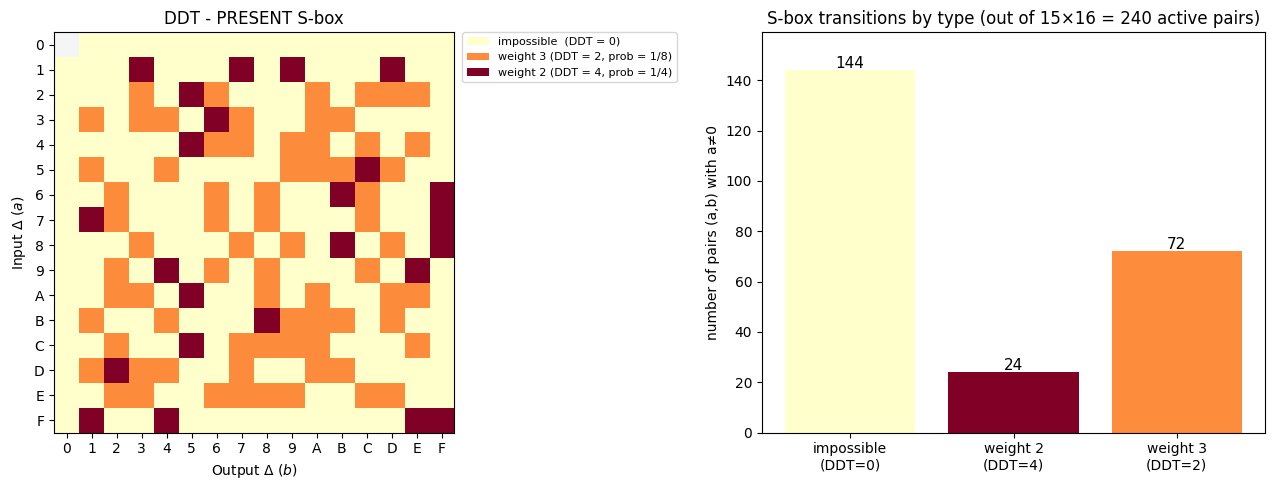

MDP = 4/16 = 1/4  =>  min weight per active S-box = 2
Active transitions: 96  (of which 72 heavy, DDT=2)


In [5]:
# Display the DDT of the PRESENT S-box

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
cmap = plt.cm.YlOrRd
norm = plt.Normalize(vmin=0, vmax=4)
ddt_display = np.array(DDT, dtype=float)
ddt_display[0, 0] = np.nan
cmap.set_bad("whitesmoke")
ax.imshow(ddt_display, cmap=cmap, norm=norm, aspect='equal')

ax.set_xticks(range(16)); ax.set_xticklabels([f'{i:X}' for i in range(16)])
ax.set_yticks(range(16)); ax.set_yticklabels([f'{i:X}' for i in range(16)])
ax.set_xlabel('Output $\\Delta$ ($b$)')
ax.set_ylabel('Input $\\Delta$ ($a$)')
ax.set_title('DDT - PRESENT S-box')

ax.legend(handles=[
    Patch(facecolor=cmap(norm(0)), label='impossible  (DDT = 0)'),
    Patch(facecolor=cmap(norm(2)), label='weight 3 (DDT = 2, prob = 1/8)'),
    Patch(facecolor=cmap(norm(4)), label='weight 2 (DDT = 4, prob = 1/4)'),
], fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

impossible = sum(1 for a in range(1, 16) for b in range(16) if DDT[a][b] == 0)
w2_count   = sum(1 for a in range(1, 16) for b in range(16) if DDT[a][b] == 4)
w3_count   = sum(1 for a in range(1, 16) for b in range(16) if DDT[a][b] == 2)

ax2 = axes[1]
bars = ax2.bar(
    ['impossible\n(DDT=0)', 'weight 2\n(DDT=4)', 'weight 3\n(DDT=2)'],
    [impossible, w2_count, w3_count],
    color=[cmap(norm(0)), cmap(norm(4)), cmap(norm(2))]
)
for bar, val in zip(bars, [impossible, w2_count, w3_count]):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, str(val),
             ha='center', fontsize=11)
ax2.set_ylabel('number of pairs (a,b) with a≠0')
ax2.set_title('S-box transitions by type (out of 15×16 = 240 active pairs)')
ax2.set_ylim(0, max(impossible, w2_count, w3_count) + 15)

plt.tight_layout()
plt.show()
print(f"MDP = {DDT[1:].max()}/16 = 1/4  =>  min weight per active S-box = 2")
print(f"Active transitions: {w2_count + w3_count}  (of which {w3_count} heavy, DDT=2)")


The computed DDT matches the results found in the literature exactly (papers 1 and 3).

*DDT of the PRESENT S-box (inputs/outputs in hexadecimal, generated from `present_sat/present.py`):*

| in \ out | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | A | B | C | D | E | F |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 0 | 16 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 |
| 1 | 0 | 0 | 0 | 4 | 0 | 0 | 0 | 4 | 0 | 4 | 0 | 0 | 0 | 4 | 0 | 0 |
| 2 | 0 | 0 | 0 | 2 | 0 | 4 | 2 | 0 | 0 | 0 | 2 | 0 | 2 | 2 | 2 | 0 |
| 3 | 0 | 2 | 0 | 2 | 2 | 0 | 4 | 2 | 0 | 0 | 2 | 2 | 0 | 0 | 0 | 0 |
| 4 | 0 | 0 | 0 | 0 | 0 | 4 | 2 | 2 | 0 | 2 | 2 | 0 | 2 | 0 | 2 | 0 |
| 5 | 0 | 2 | 0 | 0 | 2 | 0 | 0 | 0 | 0 | 2 | 2 | 2 | 4 | 2 | 0 | 0 |
| 6 | 0 | 0 | 2 | 0 | 0 | 0 | 2 | 0 | 2 | 0 | 0 | 4 | 2 | 0 | 0 | 4 |
| 7 | 0 | 4 | 2 | 0 | 0 | 0 | 2 | 0 | 2 | 0 | 0 | 0 | 2 | 0 | 0 | 4 |
| 8 | 0 | 0 | 0 | 2 | 0 | 0 | 0 | 2 | 0 | 2 | 0 | 4 | 0 | 2 | 0 | 4 |
| 9 | 0 | 0 | 2 | 0 | 4 | 0 | 2 | 0 | 2 | 0 | 0 | 0 | 2 | 0 | 4 | 0 |
| A | 0 | 0 | 2 | 2 | 0 | 4 | 0 | 0 | 2 | 0 | 2 | 0 | 0 | 2 | 2 | 0 |
| B | 0 | 2 | 0 | 0 | 2 | 0 | 0 | 0 | 4 | 2 | 2 | 2 | 0 | 2 | 0 | 0 |
| C | 0 | 0 | 2 | 0 | 0 | 4 | 0 | 2 | 2 | 2 | 2 | 0 | 0 | 0 | 2 | 0 |
| D | 0 | 2 | 4 | 2 | 2 | 0 | 0 | 2 | 0 | 0 | 2 | 2 | 0 | 0 | 0 | 0 |
| E | 0 | 0 | 2 | 2 | 0 | 0 | 2 | 2 | 2 | 2 | 0 | 0 | 2 | 2 | 0 | 0 |
| F | 0 | 4 | 0 | 0 | 4 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 4 | 4 |

### 2.b - SAT encoding

A differential path over $R$ rounds is a tuple $(\Delta_0, \Delta_1, \ldots, \Delta_R)$ where each $\Delta_r$ is a 64-bit vector. For each S-box $s$ at round $r$, the (input, output) pair must satisfy $\text{DDT}[a][b] > 0$.

The approach consists in encoding each constraint $\text{DDT}[a][b] = 0$ as a SAT clause forbidding the assignment $(\text{input}=a, \text{output}=b)$. A SAT solver (CaDiCaL or Kissat) can then find a valid path or prove that none exists.

#### SAT variables

Three families of Boolean variables are introduced:

| Variable | Formula | Semantics |
|---|---|---|
| `diff_var(r, i)` | $1 + r \cdot 64 + i$ | bit $i$ of $\Delta_r$ |
| `active_var(R, r, s)` | offset + $r \cdot 16 + s$ | 1 if S-box $s$ at round $r$ is active ($\Delta \neq 0$) |
| `heavy_var(R, r, s)` | offset + $R \cdot 16 + r \cdot 16 + s$ | 1 if the transition has DDT=2 (weight 3 instead of 2) |

The total weight of a path is $\sum_s 2 \cdot \text{active} + \text{heavy}$, which makes it possible to express a pseudo-Boolean `atmost` constraint on the total weight.

#### Optimisation: Quine-McCluskey (QM)

The naive approach generates one clause per invalid pair $(a, b)$ with $\text{DDT}[a][b] = 0$. Over 8 bits (4 for $a$, 4 for $b$), this amounts to about 160 clauses per S-box. The computation then becomes too long from R > 10 onwards (about 3h).

The **Quine-McCluskey** algorithm reduces this number by grouping several invalid minterms into a single *prime implicant*: if two minterms differ in only one bit and no valid minterm lies in their neighbourhood, they can be merged into a term with that bit as "don't care". The process is repeated until saturation, then a minimal subset of prime implicants is selected to cover all invalid minterms.

For example, if $(a=\texttt{0001}, b=\texttt{0011})$ and $(a=\texttt{0001}, b=\texttt{0111})$ are both invalid, they are merged into $a=\texttt{0001}, b=\texttt{\_011}$ - a single clause instead of two.


In [6]:
# Comparison: naive encoding vs QM
naive_count = sum(1 for a in range(16) for b in range(16) if DDT[a][b] == 0)
qm_8bit  = len(_SBOX_PI_TEMPLATES)
qm_10bit = len(_SBOX_WEIGHT_TEMPLATES)

print(f"Naive encoding           : {naive_count:3d} clauses / S-box")
print(f"QM 8-bit  (build_model)  : {qm_8bit:3d} clauses / S-box  (gain ×{naive_count/qm_8bit:.1f})")
print(f"QM 10-bit (weighted)     : {qm_10bit:3d} clauses / S-box")
print()
# CNF sizes for R=1..5
print(f"{'R':>3}  {'vars':>6}  {'clauses (build_model)':>22}  {'clauses (weighted)':>20}")
print("-" * 58)
for r in range(1, 6):
    m  = build_model(r)
    mw = build_weighted_model(r)
    print(f"{r:>3}  {m.nv:>6}  {len(m.clauses):>22}  {len(mw.clauses):>20}")

Naive encoding           : 159 clauses / S-box
QM 8-bit  (build_model)  :  41 clauses / S-box  (gain ×3.9)
QM 10-bit (weighted)     :  64 clauses / S-box

  R    vars   clauses (build_model)    clauses (weighted)
----------------------------------------------------------
  1     144                     738                  1026
  2     224                    1474                  2050
  3     304                    2210                  3074
  4     384                    2946                  4098
  5     464                    3682                  5122


**We now have a complete and (relatively) optimised model. All that is missing is an efficient search algorithm.**

### 2.c — Search algorithms

Two successive algorithms exploit the CNF model to compute the optimal bounds.

**Algorithm 1 — Minimum active S-boxes** (`find_min_active_sbox`)

A **binary search** is performed on $k$: at each iteration, the constraint `CardEnc.atmost(active_vars, bound=k)` is added to the base CNF, encoded via an **assumption literal** so that it can be removed at the next iteration without rebuilding the problem. Complexity: $O(\log(16R))$ SAT calls.

**Algorithm 2 — Minimum weight** (`find_min_trail_weight`)

1. We compute $k^* = \text{min\_active}(R)$, which gives the lower bound $W_{\min} \geq 2k^*$ (and $W_{\min} \geq W_{\min}(R{-}1) + 2$ since each additional round contributes at least 2).
2. An **ascending linear search** tests $W = W_{\text{lo}}, W_{\text{lo}}+1, \ldots$ by adding `PBEnc.atmost(lits, weights, bound=W)` until SAT is obtained.

The pseudo-Boolean constraint encodes $\sum_{s,r} 2 \cdot a_{s,r} + h_{s,r} \leq W$, with $a_{s,r}$ = `active_var` (weight 2) and $h_{s,r}$ = `heavy_var` (extra weight 1 for DDT=2 transitions).

**Solver choice.** Two solvers were compared: **CaDiCaL**, which natively supports incrementality (learned clauses are kept across successive calls on the same instance), and **Kissat**, which does not and rebuilds the solver at each iteration. In theory, incrementality should favour CaDiCaL in an ascending linear search. In practice, **Kissat remains significantly faster** on all our instances (see the benchmarks in section 3.c). We therefore use Kissat as the default solver, despite losing the theoretical benefit of reusing learned clauses.

#### Lower bound optimisation

**Lemma.** For PRESENT, $w_{\min}(R) \geq w_{\min}(R-1) + 2$ for all $R \geq 2$.

*Proof.* Let $\Delta_0 \to \cdots \to \Delta_R$ be an optimal trail of weight $w_{\min}(R)$, with $\Delta_0 \neq 0$. The prefix $\Delta_0 \to \cdots \to \Delta_{R-1}$ has weight $\geq w_{\min}(R-1)$. It therefore suffices to show that the last round contributes $\geq 2$, i.e. that $\Delta_{R-1} \neq 0$.

Since the PRESENT S-box is bijective, $\Delta X = 0 \Leftrightarrow \Delta Y = 0$ (Wei et al., ePrint 2012/214, Lemma 6). The `pLayer` and `AddRoundKey` preserve nullity. If $\Delta_{R-1} = 0$, then by backward induction $\Delta_0 = 0$ - a contradiction. Hence $\Delta_{R-1} \neq 0$, at least one S-box is active at round $R$, and it contributes a weight $\geq 2$.

## 3 - Results

The results are presented in three parts: the minimum number of active S-boxes, the minimum weight of differential paths, then the extraction of an optimal path. For $R \leq 8$, the computations run directly in the notebook. For larger values, the results are cached.

### 3.a - Minimum active S-boxes

The number of active S-boxes in a differential path provides a **lower bound on the weight**: each active S-box contributes at least 2, the maximum DDT probability being 4/16 = 1/4. Minimising this number is therefore a first step before searching for the exact weight.

The binary search described in 2.c is applied with CaDiCaL. Computation times grow steadily with $R$, with a few irregularities (for example $R=28$ is solved faster than $R=27$), probably due to the clauses learned by the solver, which vary from one instance to another.

In [7]:
# Minimum number of active S-boxes for R=1..6
print(f"{'R':>3}  {'min_active':>10}  {'time':>8}")
print("-" * 26)
for r in range(1, 7):
    t0 = time.time()
    k, _ = find_min_active_sbox(r, solver="cadical", return_trail=True)
    t = time.time() - t0
    print(f"{r:>3}  {k:>10}  {t:>7.3f}s")

  R  min_active      time
--------------------------
  1           1    0.001s
  2           2    0.003s
  3           4    0.008s
  4           6    0.040s
  5          10    0.333s
  6          12    0.541s


The computation time for rounds 1 to 31 is about 30 minutes. The full table is displayed below from the benchmark.json file.

In [8]:
# Full results (Kissat, R=1..31)
# Total time: about 30 minutes.
print(f"{'R':>3}  {'min_active':>10}  {'time':>10}")
print("-" * 27)


total_time = 0
for row in benchmark['min_active_kissat']:
    r = int(row)
    k = benchmark['min_active_kissat'][row]['min_active']
    t = benchmark['min_active_kissat'].get(str(r), {}).get('time')
    total_time += t
    print(f"{r:>3}  {k:>10}  {t:>9.3f}s")

print(f"\nmin_active(R) = 2R for R ≥ 2  (except R=1 where min_active=1)")
print(f"Total time: {total_time/60:.1f} min")


  R  min_active        time
---------------------------
  1           1      0.002s
  2           2      0.008s
  3           4      0.036s
  4           6      0.143s
  5          10      0.578s
  6          12      1.636s
  7          14      1.492s
  8          16      3.292s
  9          18      4.999s
 10          20     10.887s
 11          22      8.395s
 12          24     13.879s
 13          26     21.770s
 14          28     21.770s
 15          30     27.854s
 16          32     47.221s
 17          34     50.054s
 18          36     59.023s
 19          38     74.243s
 20          40     65.174s
 21          42     83.117s
 22          44     99.815s
 23          46    113.013s
 24          48     93.366s
 25          50     91.685s
 26          52    137.346s
 27          54    117.982s
 28          56    120.660s
 29          58    166.530s
 30          60    153.061s
 31          62    169.384s

min_active(R) = 2R for R ≥ 2  (except R=1 where min_active=1)
Total time: 2

These results match those found in the literature (paper 5).

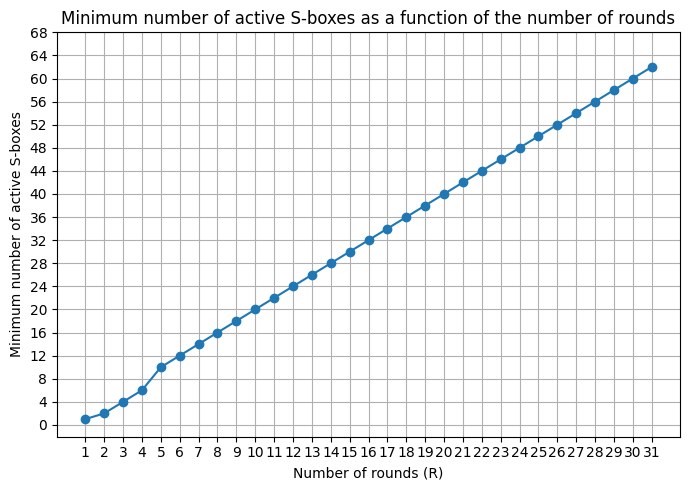

In [9]:
# Minimum number of active S-boxes as a function of the number of rounds R
rounds = [i for i in range(1, 32)]
min_active = []

for r in benchmark['min_active_kissat']:
    min_active.append(benchmark['min_active_kissat'][r]['min_active'])

plt.figure(figsize=(7, 5))
plt.plot(rounds, min_active, marker='o')
plt.title('Minimum number of active S-boxes as a function of the number of rounds')
plt.xlabel('Number of rounds (R)')
plt.ylabel('Minimum number of active S-boxes')
plt.xticks(rounds)
plt.yticks(np.arange(0, 70, 4))
plt.grid()
plt.tight_layout()
plt.show()

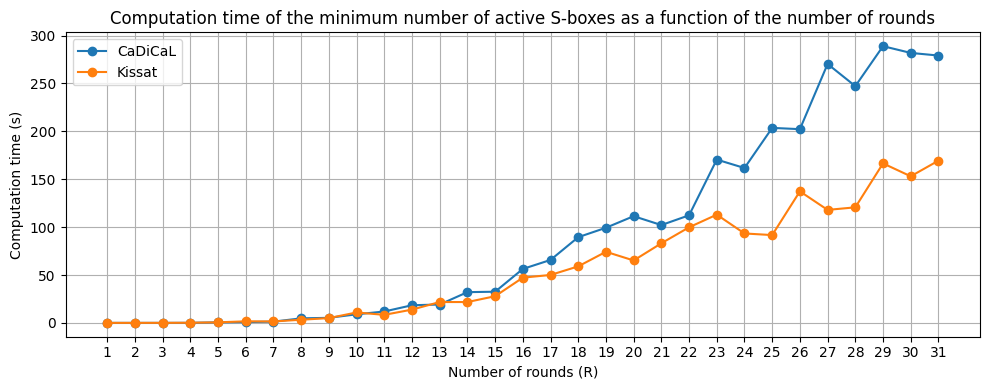

In [10]:
# Comparison of the computation times of the minimum number of active S-boxes as a function of the number of rounds, for CaDiCaL and Kissat
rounds = [i for i in range(1, 32)]
cadical_times = []
kissat_times = []

for r in benchmark['min_active_cadical']:
    cadical_times.append(benchmark['min_active_cadical'][r]['time'])
for r in benchmark['min_active_kissat']:
    kissat_times.append(benchmark['min_active_kissat'][r]['time'])

plt.figure(figsize=(10, 4))
plt.plot(rounds, cadical_times, marker='o', label='CaDiCaL')
plt.plot(rounds, kissat_times, marker='o', label='Kissat')
plt.title('Computation time of the minimum number of active S-boxes as a function of the number of rounds')
plt.xlabel('Number of rounds (R)')
plt.ylabel('Computation time (s)')
plt.xticks(rounds)
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

*The command used is:* 
```sh
uv run python3 -m present_sat --active --rmax 31 --solver kissat
```

### 3.b - Minimum weight of differential paths

Once the minimum number of active S-boxes is known, we look for the actual **minimum weight** of an $R$-round path, which corresponds to the best attainable differential probability.

We know that $w_{\min}(R) \geq 2 \times \text{min\_active}(R)$, but this bound is not always reached. In some cases, the structure of the cipher forces at least one DDT=2 transition (weight 3 instead of 2), creating a **gap** between the bound and the actual minimum.

This is what we observe from $R=10$: the minimum weight is 41 whereas $2 \times 20 = 40$. This gap grows in steps until it reaches 12 at $R=26$.

**Main result:** from $R=15$ on, $w_{\min} = 66 > 64$. Any differential attack on 15 rounds or more requires more than $2^{65}$ plaintext pairs - which exceeds the size of the plaintext space. PRESENT is therefore resistant to differential cryptanalysis from 15 rounds on.

Computations for $R > 10$ can take from a few minutes to several hours; the results are cached below.

In [11]:
# Minimum weight for R=1..10
# About 20s of execution
print(f"{'R':>3} | {'2*min_active_sbox':17} | {'min_weight':>10} | {'time':>8}  | {'gap':>3}")
print("-" * 55)
for r in range(1, 11):
    t0 = time.time()
    w = find_min_trail_weight(r)
    t = time.time() - t0
    bound = 2 * ACTIVE_BOUNDS[r]
    gap = w - bound
    print(f"{r:>3} | {bound:>17} | {w:>10} | {t:>8.3f}s | {gap:>3}  {'<' if gap else ''}")

  R | 2*min_active_sbox | min_weight |     time  | gap
-------------------------------------------------------
  1 |                 2 |          2 |    0.002s |   0  
  2 |                 4 |          4 |    0.007s |   0  
  3 |                 8 |          8 |    0.043s |   0  
  4 |                12 |         12 |    0.082s |   0  
  5 |                20 |         20 |    0.155s |   0  
  6 |                24 |         24 |    0.795s |   0  
  7 |                28 |         28 |    0.823s |   0  
  8 |                32 |         32 |    1.340s |   0  
  9 |                36 |         36 |    3.830s |   0  
 10 |                40 |         41 |   11.809s |   1  <


We indeed observe that at round 10, the gap between 2 * min_active_sbox and min_weight is 1. So one S-box is forced to have weight 3 among the 20 active ones.

In [12]:
# Full results (Kissat, R=1..31)
print(f"{'R':>3}  {'min_active':>10}  {'2*active':>8}  {'min_weight':>10}  {'gap':>4}  {'time':>11}")
print("-" * 56)

r_secure = sys.maxsize
w_secure = None
total_time = 0

for r in sorted(benchmark['min_weight_kissat_seq'], key=int):
    row = benchmark['min_weight_kissat_seq'][r]
    a = benchmark['min_active_cadical'][r]['min_active']
    w = row['min_weight']
    gap = w - 2 * a

    t = row['time']
    total_time += t

    suffix = ""
    if w > 64 and int(r) < r_secure:
        w_secure = w
        r_secure = int(r)
        suffix = "  <- threshold w > 64"

    print(f"{r:>3}  {a:>10}  {2*a:>8}  {w:>10}  {gap:>4}  {t:>10.3f}s{suffix}")

print()
print(f"Security threshold reached at R={r_secure}  (w_min={w_secure} > 64)")
print(f"Total computation time: {total_time/3600:.1f}h")


  R  min_active  2*active  min_weight   gap         time
--------------------------------------------------------
  1           1         2           2     0       0.006s
  2           2         4           4     0       0.011s
  3           4         8           8     0       0.052s
  4           6        12          12     0       0.088s
  5          10        20          20     0       0.170s
  6          12        24          24     0       1.281s
  7          14        28          28     0       0.880s
  8          16        32          32     0       1.412s
  9          18        36          36     0       4.379s
 10          20        40          41     1      12.911s
 11          22        44          46     2     116.060s
 12          24        48          52     4      77.303s
 13          26        52          56     4     120.685s
 14          28        56          62     6     453.334s
 15          30        60          66     6     373.606s  <- threshold w > 64
 16       

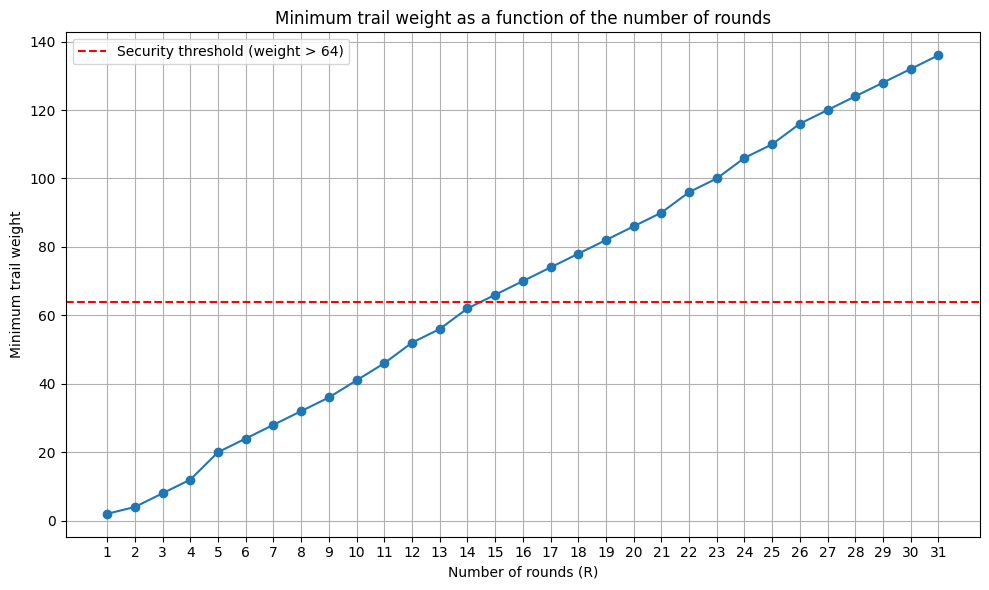

In [13]:
rounds = []
min_weights = []
for r in sorted(benchmark['min_weight_kissat_seq'], key=int):
    row = benchmark['min_weight_kissat_seq'][r]
    w = row['min_weight']
    rounds.append(int(r))
    min_weights.append(w)
plt.figure(figsize=(10, 6))
plt.plot(rounds, min_weights, marker='o')
plt.axhline(64, color='red', linestyle='--', label='Security threshold (weight > 64)')
plt.title('Minimum trail weight as a function of the number of rounds')
plt.xlabel('Number of rounds (R)')
plt.ylabel('Minimum trail weight')
plt.xticks(rounds)
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

We clearly see that the security threshold (weight > 64) is reached from R=15 on.

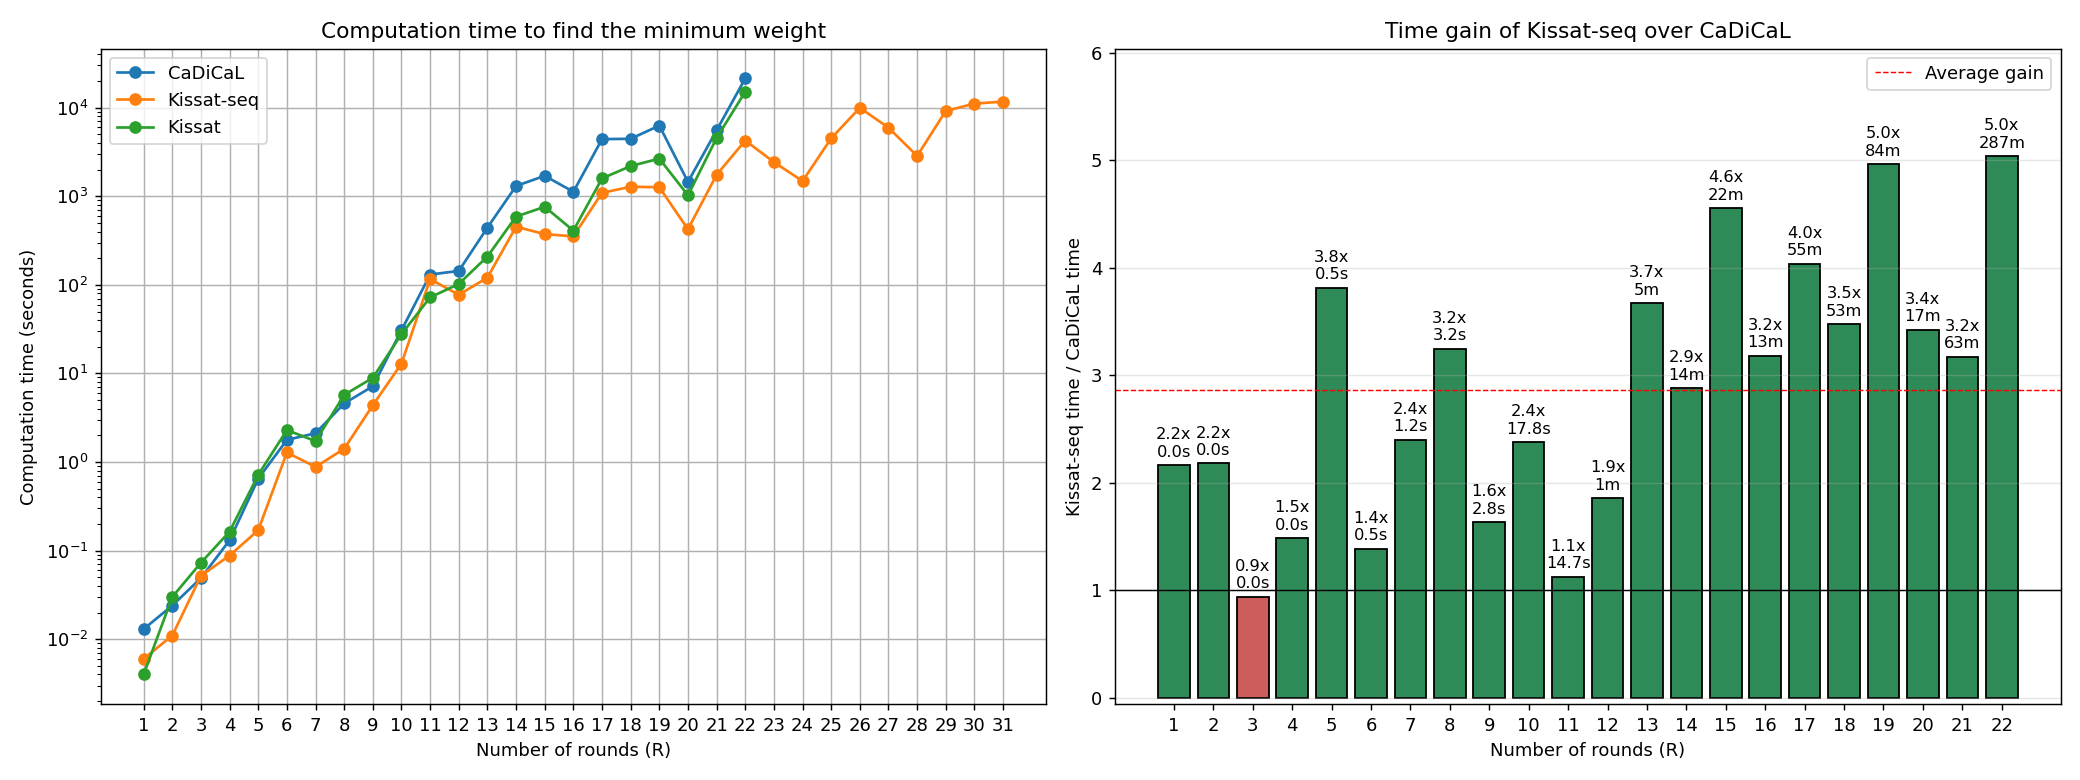

In [14]:

# Comparison of the CaDiCaL and Kissat solvers for the minimum trail weight
fmt = lambda s: f"{s/60:.0f}m" if s >= 60 else f"{s:.1f}s"

r, tc, tko, tk, df, ds = [], [], [], [], [], []
for rk in sorted(benchmark['min_weight_kissat_seq'], key=int):
    ro = benchmark['min_weight_kissat_seq'][rk]
    rc = benchmark['min_weight_cadical'].get(rk, {'time': None})
    rk = int(rk)
    
    df.append(rc['time'] / ro['time'] if rc['time'] else None)
    ds.append(rc['time'] - ro['time'] if rc['time'] else None)
    
    r.append(rk)
    tc.append(rc['time'])
    tko.append(ro['time'])
    tk.append(benchmark['min_weight_kissat'].get(str(rk), {}).get('time'))

rd = [x for x, d in zip(r, df) if d]
df = [d for d in df if d]
ds = [s for s in ds if s]
c = ['seagreen' if d > 1 else 'indianred' for d in df]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.plot(r, tc, 'o-', label='CaDiCaL')
ax1.plot(r, tko, 'o-', label='Kissat-seq')
ax1.plot(r, tk, 'o-', label='Kissat')
ax1.set(title='Computation time to find the minimum weight', 
        xlabel='Number of rounds (R)', ylabel='Computation time (seconds)',
        xticks=r, yscale='log')
ax1.grid(), ax1.legend()

bars = ax2.bar(rd, df, color=c, edgecolor='black')
ax2.axhline(1, color='black', linewidth=0.8)
ax2.axhline(np.mean(df), color='red', linestyle='--', linewidth=0.8, label='Average gain')

for bar, d, s in zip(bars, df, ds):
    h = bar.get_height()
    ax2.annotate(f"{d:.1f}x\n{fmt(abs(s))}", 
                 xy=(bar.get_x() + bar.get_width()/2, h),
                 xytext=(0, 3 if h > 0 else -3), textcoords='offset points',
                 ha='center', va=('bottom' if h > 0 else 'top'), fontsize=9)

ax2.set_ylim(min(df)-1, max(df)+1)
ax2.set(title='Time gain of Kissat-seq over CaDiCaL',
        xlabel='Number of rounds (R)', ylabel='Kissat-seq time / CaDiCaL time',
        xticks=rd)
ax2.grid(axis='y', alpha=0.3)
ax2.legend()
plt.tight_layout()
plt.show()

For the given problem, Kissat is **much** better than CaDiCaL (by a factor of 1.1 to 5).

As explained in section 2.b, we use a technique that gives a better approximation of the lower bound of the minimum weight, which greatly reduces the computation time. **Kissat-seq** denotes the computation times with this optimisation.


However, using this technique requires the minimum weights to be computed sequentially, round by round. Indeed, to compute the lower bound at R, one must use the minimum weight found for R-1. It is therefore no longer possible to parallelise the execution in this specific case.

### 3.c - Extracting an optimal differential path

When the solver returns SAT for a weight $W$, its model (a list of positive/negative literals) encodes the whole differential path. The `decode_trail` function reads the `diff_var(r, i)` variables to reconstruct the $R+1$ 64-bit words $\Delta_0, \ldots, \Delta_R$.

To validate the extracted path, we check that for each S-box $s$ and each round $r$, the (input nibble, output nibble after P-layer) pair indeed satisfies $\text{DDT} > 0$. The output after the P-layer is computed as follows:
$$b_j = \text{bit}_{P[4s+j]}(\Delta_{r+1}), \quad j = 0,\ldots,3$$

The actual weight of the path is then computed from the `active_var` and `heavy_var` variables of the model: $w = \sum_{s,r} 2 \cdot a_{s,r} + h_{s,r}$.


In [15]:
# Compute the differential trails
# Compute both trails
# About 15s of execution
configs = [(7, "kissat"), (10, "cadical")]
trails = []

for R, solver in configs:
    t0 = time.time()
    W, trail = find_min_trail_weight(R, return_trail=True, solver=solver)
    elapsed = time.time() - t0
    weight = trail_weight(trail)

    print(f"Optimal trail - R={R}, weight W={W}  ({elapsed:.3f}s)\n")
    print(f"{'Round':>6} | {'Δ_r':^18}")
    print("-" * 27)
    for i, delta in enumerate(trail):
        print(f"{i:>6} | {delta:#018x}")
    print(f"\nvalidate_trail  : {'ok' if validate_trail(trail, R) else 'INVALID'}")
    print(f"Active S-boxes  : {trail_active_sboxes(trail)}")
    print(f"total weight    : {weight}  (expected {W})")
    print(f"probability     : 2^(-{weight})")
    print("\n" + "=" * 40 + "\n")

    trails.append((trail, R, W))

Optimal trail - R=7, weight W=28  (0.775s)

 Round |        Δ_r        
---------------------------
     0 | 0x000d00000000000d
     1 | 0x0000000010010000
     2 | 0x0090000000000090
     3 | 0x0000200200000000
     4 | 0x0000090000000900
     5 | 0x0000040400000000
     6 | 0x0000050000000500
     7 | 0x0404040400000000

validate_trail  : ok
Active S-boxes  : 14
total weight    : 28.0  (expected 28)
probability     : 2^(-28.0)


Optimal trail - R=10, weight W=41  (14.456s)

 Round |        Δ_r        
---------------------------
     0 | 0x0000000000007007
     1 | 0x0000000000000009
     2 | 0x0000000100000000
     3 | 0x0100000000000100
     4 | 0x4004000000004004
     5 | 0x0000900900009009
     6 | 0x0000090900000000
     7 | 0x0000050000000000
     8 | 0x0000040000000000
     9 | 0x0000040000000400
    10 | 0x0000040400000404

validate_trail  : ok
Active S-boxes  : 20
total weight    : 41.0  (expected 41)
probability     : 2^(-41.0)




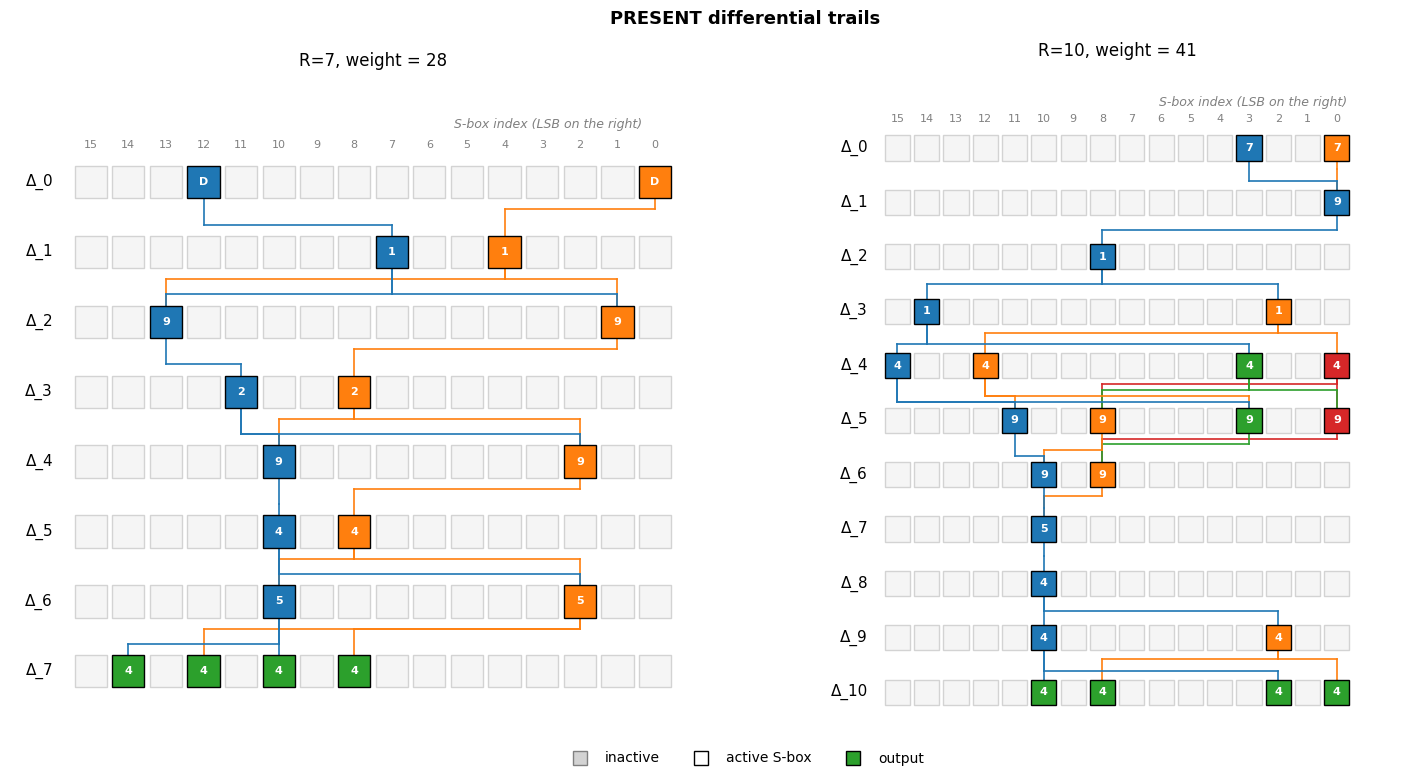

In [16]:
# Display the differential trails
def out_nibble(s, d_out):
    return (d_out >> (4 * s)) & 0xF

P_COL = plt.get_cmap('tab10').colors
SQ, ROW, COL, BAND = 0.6, 1.3, 0.7, (1.3 - 0.6) * 0.8

xp = lambda s: (15 - s) * COL
yp = lambda r: -r * ROW


def plot_trail(ax, trail, R, W):
    a, w, i = [], [], []
    for r in range(R):
        d_in, d_out = trail[r], trail[r + 1]
        al, wd, id_ = [], {}, {}
        for s in range(16):
            nib = (d_in >> (4 * s)) & 0xF
            if nib:
                al.append(s)
                id_[s], b = nib, out_nibble(s, d_out)
                wd[s] = 2 if DDT[nib][b] == 4 else 3
        a.append(al); w.append(wd); i.append(id_)

    fo = {s: (trail[R] >> (4*s)) & 0xF for s in range(16) if (trail[R] >> (4*s)) & 0xF}
    gc = lambda r, s: P_COL[sorted(a[r], key=xp).index(s) % 10]

    for r in range(R):
        for s_src in a[r]:
            sa = sorted(a[r], key=xp)
            idx, n = sa.index(s_src), len(a[r])
            offset = -BAND/2 + (idx + 0.5) * (BAND / n)
            y1, y2 = yp(r) - SQ/2, yp(r+1) + SQ/2
            ym = (y1 + y2) / 2 + offset
            x1, col = xp(s_src), gc(r, s_src)
            for k in range(4):
                if (trail[r+1] >> P[4*s_src + k]) & 1:
                    s_dst = P[4*s_src + k] // 4
                    if (r+1 < R and s_dst in a[r+1]) or (r+1 == R and s_dst in fo):
                        x2 = xp(s_dst)
                        ax.plot([x1, x1], [y1, ym], color=col, lw=1.2, zorder=1)
                        ax.plot([x1, x2], [ym, ym], color=col, lw=1.2, zorder=1)
                        ax.plot([x2, x2], [ym, y2], color=col, lw=1.2, zorder=1)

    for r in range(R):
        for s in range(16):
            x, y = xp(s), yp(r)
            if s in a[r]:
                ax.add_patch(Rectangle((x-SQ/2, y-SQ/2), SQ, SQ, fc=gc(r,s), ec='black', zorder=3))
                ax.text(x, y, f"{i[r][s]:X}", ha='center', va='center', fontsize=8, color='white', fontweight='bold', zorder=4)
            else:
                ax.add_patch(Rectangle((x-SQ/2, y-SQ/2), SQ, SQ, fc='whitesmoke', ec='lightgray', zorder=3))

    for s in range(16):
        x, y = xp(s), yp(R)
        if s in fo:
            ax.add_patch(Rectangle((x-SQ/2, y-SQ/2), SQ, SQ, fc='C2', ec='black', zorder=3))
            ax.text(x, y, f"{fo[s]:X}", ha='center', va='center', fontsize=8, color='white', fontweight='bold', zorder=4)
        else:
            ax.add_patch(Rectangle((x-SQ/2, y-SQ/2), SQ, SQ, fc='whitesmoke', ec='lightgray', zorder=3))

    for r in range(R + 1):
        ax.text(-0.7, yp(r), f"Δ_{r}", ha='right', va='center', fontsize=11)
    for s in range(16):
        ax.text(xp(s), 0.7, str(s), ha='center', va='center', fontsize=8, color='gray')
    ax.text(8.5, 1, "S-box index (LSB on the right)", ha='center', fontsize=9, color='gray', style='italic')
    ax.set_title(f"R={R}, weight = {W}")
    ax.set_xlim(-1.5, 12); ax.set_ylim(yp(R) - 0.9, 2)
    ax.set_aspect('equal'); ax.axis('off')


(trail1, R1, W1), (trail2, R2, W2) = trails
fig, axes = plt.subplots(1, 2, figsize=(15, 8))
plot_trail(axes[0], trail1, R1, W1)
plot_trail(axes[1], trail2, R2, W2)

# Shared legend at the bottom
handles = [Line2D([0],[0], marker='s', color='w', markerfacecolor=c, markeredgecolor=e, markersize=10, label=l)
           for c, e, l in [('lightgray','gray','inactive'), ('white','black','active S-box'), ('C2','black','output')]]
fig.legend(handles=handles, loc='lower center', ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.02))

fig.suptitle("PRESENT differential trails", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.subplots_adjust(bottom=0.08)
plt.savefig("trails_compare.png", dpi=240, bbox_inches='tight')
plt.show()

### Trail analysis (R=7 and R=10)

**Direct comparison.** The R=7 trail reaches a weight of 28, i.e. $2 \times 14$: the bound $w_{\min} = 2 \cdot A(R)$ is tight and all transitions have weight 2 (visible in blue and orange only). The R=10 trail reaches a weight of 41, i.e. $2 \times 20 + 1$: for the first time, a weight-3 transition appears (red cell at $\Delta_4$). This is the threshold where the active S-box bound ceases to be attainable.

**Forced appearance of weight 3.** The single weight-3 transition at R=10 is not a choice of the solver: it is a structural necessity. Over 10 rounds, no trail simultaneously avoids expansion through the `pLayer` and the exclusive use of DDT = 4 transitions. This heavy transition appears early in the trail (round 5 out of 10).

**General shape.** Both trails follow a characteristic expansion-contraction pattern. At R=7, diffusion is fast (1 -> 2 -> 4 active S-boxes in 3 rounds) and then stabilises around 2 S-boxes per round. At R=10, the expansion reaches a wider peak (4 active S-boxes at $\Delta_4$) before contracting again.

**Recurring values.** The same nibbles (`1`, `4`, `9`, `D`) reappear in both trails. These values correspond to the differences for which the PRESENT DDT reaches its maximum non-trivial value (4); the solver systematically favours them to minimise the weight, regardless of the length of the trail.

**Probabilities.** The resulting probabilities are $2^{-28}$ for R=7 and $2^{-41}$ for R=10, both very far from the security threshold $2^{-64}$. We have to wait until $R = 15$ ($w_{\min} = 66$) to cross this threshold, as seen above.

## 4 — Conclusion

We modelled the search for minimum-weight differential paths on PRESENT as a SAT problem, and exploited two optimisations that proved decisive for solver efficiency:

1. **Compact S-box encoding via Quine-McCluskey minimisation.** The clauses characterising the differential propagation of the S-box are computed once, over the space of transitions (8 bits, or 10 bits when the weight is also encoded). This encoding reduces the number of clauses by a factor of about 3.9 compared to a naive encoding enumerating all transitions.

2. **Lower bound optimisation.** The lower bound is computed from the minimum weight found for the previous number of rounds. From round 15 on, this new bound is greater than the plain 2 * min_active and therefore reduces the number of increments before reaching the result, saving several tens of minutes, or even hours, for the last rounds.

### Main results

| Property | Value | Interpretation |
|---|---|---|
| $A_{\min}(5) = 10$ | confirmed | Experimental validation of the theorem of Bogdanov et al. (2007) |
| $w_{\min}(R) = 2 A_{\min}(R)$ for $R \leq 9$ | bound reached | All active S-boxes use a weight-2 transition (DDT = 4) |
| $w_{\min}(10) = 41$ | bound exceeded | At least one weight-3 transition (DDT = 2) becomes unavoidable |
| $w_{\min}(R) > 64$ for $R \geq 15$ | security threshold | PRESENT resists differential cryptanalysis from 15 rounds on, i.e. fewer than half of the 31 rounds of the full cipher |
| $w_{\min}(31) = 136$ | comfortable margin | More than twice the security threshold |

### Limitations and perspectives

The solving time grows exponentially with the number of rounds, which limits the approach to around $R \approx 25$ for a general-purpose CDCL solver. Two more specialised directions make it possible to go beyond:

- **DFS branch-and-bound with PC1 / PC2 bounds** (Kim et al., ToSC 2022). Lower bounds are computed inductively from the results of previous rounds, and differential propagation is exploited to prune the search tree aggressively. This approach reaches the full 31 rounds of PRESENT in a few seconds.

- **MILP modelling.** The differential constraints of the DDT are encoded as linear inequalities on the binary state variables. This approach is integrated in tools such as CLAASP for word-oriented ciphers (AES, SKINNY); its extension to bit-oriented ciphers such as PRESENT, due to Sun et al. (2014), remains the state of the art for computing complete bounds.

### Main references

The main references used are in the papers folder.